In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, accuracy_score
from sklearn.utils import resample
from sklearn.feature_selection import SelectKBest

from scipy.stats import ttest_ind, wilcoxon

from datasets.Harmonized_Datasets import harmonize

import pylimma 
import decoupler as dc
import gseapy as gp

import starbars

from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.ds import DeseqStats

from statsmodels.stats.multitest import multipletests


/home/braemp4/.cache/pypoetry/virtualenvs/venetoclax-project-Qra0yt8T-py3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# CONSTANTS
PROBABILITY_CUTOFF = (0.25, 0.75) # inclusive
RANDOM_STATE=4 
N_SPLITS=4
DESEQ_FEATURE_SELECTION = False

In [3]:
# HELPER FUNCS
def cross_val_classification(X,y_ad, model,n_splits=N_SPLITS, random_state=RANDOM_STATE, verbose=True):
   

    results = {"samples": [],
                'wes_id': [],
               "y_true": [],
               "y_pred": [],
               "y_prob": [],
               }

    fold_metrics = {
            "n_fold": [],
            "precision_score": [],
            "recall_score": [], 
            "f1_score": [],
  
            "accuracy": [],
            "roc_auc": [],
            }
    
    y = y_ad['venetoclax_response']

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    n_fold= 0
    for i, (train_index, test_index) in enumerate(skf.split(X,y)):
        if verbose:
            print(f"CV FOLD: {n_fold + 1}")

        X_train, y_train = X.iloc[train_index], y.iloc[train_index]
        X_test, y_test = X.iloc[test_index], y.iloc[test_index]


        # add ground truth values
        results["y_true"] += list(y_test)
        
        # get test samples
        test_samples = X_test.index
        results["samples"] +=list(test_samples)
        wes_ids = y_ad.loc[test_samples]['WES_SampleID']
        results['wes_id'] += list(wes_ids)
       
        

        #sele_k = SelectKBest(k=100)

        #top_features = sele_k.fit(X_train, y_train).get_feature_names_out()

        #X_train = X_train[top_features]
        #X_test = X_test[top_features]

        # Scale the training data
        scl = StandardScaler()
        X_train = scl.fit_transform(X_train)
        X_test = scl.transform(X_test)

        # train model
        model.fit(X_train, y_train)

        # get fold predictions
        y_pred = model.predict(X_test)
        results["y_pred"] +=list(y_pred)

        # get fold probas
        y_prob = model.predict_proba(X_test)[:,1]
        results["y_prob"] +=list(y_prob)

        # record fold metrics
        n_fold +=1
        fold_metrics["n_fold"].append(n_fold)
        fold_metrics["precision_score"].append(precision_score(y_test, y_pred))
        fold_metrics["recall_score"].append(recall_score(y_test, y_pred))
        fold_metrics["f1_score"].append(f1_score(y_test, y_pred))
        fold_metrics["accuracy"].append(accuracy_score(y_test,y_pred))
        fold_metrics["roc_auc"].append(roc_auc_score(y_test, y_prob))

    if verbose:
        print(pd.DataFrame(fold_metrics))

   
    return results, fold_metrics

def get_bootstrap_metrics(results_df, alpha=0.05, bootstraps=10000, verbose=True):
    results_df = results_df.copy().set_index('samples')

    
    metric_statistics= {
        'accuracy': [],
        'precision': [],
        'recall': [],
        'f1': [],
        'roc_auc': []
    }
    bootstrap_results = {
        'accuracy': (),
        'precision': (),
        'recall': (),
        'f1': (),
        'roc_auc': (),
    }

    # get bootstrap statistics
    for i in range(bootstraps):
        res = resample(results_df)

        y_pred = res['y_pred']
        y_prob = res['y_prob']
        y_true = res['y_true']

        metric_statistics['accuracy'].append(accuracy_score(y_true, y_pred))
        metric_statistics['precision'].append(precision_score(y_true, y_pred))
        metric_statistics['recall'].append(recall_score(y_true, y_pred))
        metric_statistics['f1'].append(f1_score(y_true, y_pred))
        metric_statistics['roc_auc'].append(roc_auc_score(y_true, y_prob))

    # get confidence intervals
    for key in metric_statistics.keys():
        stat = metric_statistics[key]
        stat = sorted(stat)
        
        lower = np.percentile(stat, (1-alpha) / 2)
        upper = np.percentile(stat, alpha+((1-alpha)/2))
        bootstrap_results[key] = (lower, upper)

    if verbose:
        print("ML Classification metric 95% Confidence Infervals: ")
        for key in bootstrap_results.keys():
            lower, upper = bootstrap_results[key]
            print(f"{key.replace('_', ' ').title():<12} [{lower:.3f}, {upper:.3f}]")
            
            
    return bootstrap_results 


def differential_expression_analysis(method, adata, group_label='y_pred'):
    ''' 
    adata needs group_label column
    '''
    expr = adata.to_df()
    analysis_results = {'gene':None, 't': None, 'padj':None}

   
    if method == 'limma':
        design = np.column_stack([np.ones( len(adata.obs[group_label]) ), np.array(adata.obs[group_label]) ])
        fit = pylimma.lm_fit(expr.transpose(), design)
        fit = pylimma.contrasts_fit(fit, contrasts=np.array([[0], [1]]))
        fit = pylimma.e_bayes(fit)

        results_df = pylimma.top_table(fit,coef=0, key="fit",number=np.inf,sort_by="p")
        results_df['padj'] = results_df["adj_p_value"]

        analysis_results['gene'] = results_df.index 
        analysis_results['t'] = results_df['t']
        analysis_results['padj'] = results_df['padj']
        analysis_results['log_fc'] = results_df['log_fc']
        
        
    elif method == 't_test':
        pvals = []
        stat = []
        genes = []
        fc = []
        sensitive_ad = adata[adata.obs[group_label] == 1]
        resistant_ad = adata[adata.obs[group_label] == 0]
        

        for gene in expr.columns:
            
            test =  ttest_ind(sensitive_ad.to_df()[gene], resistant_ad.to_df()[gene], alternative='two-sided')
            pvals.append(test.pvalue)
            stat.append(test.statistic)
            genes.append(gene)
            fc.append(sensitive_ad.to_df()[gene].mean() / resistant_ad.to_df()[gene].mean())

            
        padj = multipletests(pvals)[1]

        analysis_results['gene'] = genes
        analysis_results['t'] = stat
        analysis_results['padj'] = padj
        analysis_results['log_fc'] = np.log2(fc)

    
    
    analysis_results = pd.DataFrame(analysis_results)
    return  analysis_results.set_index('gene')

In [4]:
# import data
datasets = harmonize()
mf_ad = datasets['Moffitt']
cm_ad = datasets['Commpass']

/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


DeCampos Annotated data found!
Number of Harmonized Genes: 18676


In [5]:
# preprocessing
mf_ad.obs['Disease_Status'].unique()

#exclude SMOL and MGUS
mf_ad = mf_ad[(mf_ad.obs['Disease_Status'] !=  'SMOL') & (mf_ad.obs['Disease_Status'] != "MGUS")]



In [6]:
# define response groups
sens_cutoff = np.quantile(mf_ad.obs['ABT-199'],1/3)
res_cutoff = np.quantile(mf_ad.obs['ABT-199'], 2/3)

# 1 = sens, 0 = res, -1 moderate
mf_ad.obs['venetoclax_response'] = [1 if y < sens_cutoff else 0 if y > res_cutoff else -1 for y in mf_ad.obs['ABT-199']]
moderate_ad = mf_ad.copy()
moderate_ad = moderate_ad[moderate_ad.obs['venetoclax_response'] == -1]
mf_ad = mf_ad[mf_ad.obs['venetoclax_response'] != -1]


/tmp/ipykernel_13149/2362551595.py:6: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  mf_ad.obs['venetoclax_response'] = [1 if y < sens_cutoff else 0 if y > res_cutoff else -1 for y in mf_ad.obs['ABT-199']]


In [7]:
mf_ad.obs

,ABT-199,ExVivo_SampleID,patientID,t11_14,WES_SampleID,Disease_Status,venetoclax_response
RNA_SampleID,,,,,,,
SL414065,68.289579,Pt429,GDH03df143c,NaN,SL409637,ERMM,1
SL316611,96.238950,Pt227,GDH08065638,0.0,NaN,LRMM,0
SL399348,65.236880,Pt382,GDH087884bf,0.0,SL393230,ERMM,1
SL405581,62.617299,Pt398,GDH1831d487,0.0,SL399816,NDMM,1
SL340747,78.370299,Pt253,GDH1c1bbfa6,0.0,SL332445,ERMM,1
...,...,...,...,...,...,...,...
SL405724,95.078404,Pt392,GDHdec9c5ce,0.0,SL399814,ERMM,0
SL432584,65.712897,Pt495,GDHe3530ae7,NaN,SL434799,NDMM,1
SL432596,100.000000,Pt516,GDHea79fae2,NaN,SL434811,ERMM,0


In [8]:
# run deseq for feature selection
genes_selected = list(mf_ad.var_names)

if DESEQ_FEATURE_SELECTION:
    cm_ad = cm_ad[cm_ad.obs['Trans_1114'].notna()]
    cm_ad = cm_ad[cm_ad.obs['Country_Skerget'].notna()]

    expr_df = pd.DataFrame(cm_ad.layers['raw_counts'], columns=np.array(cm_ad.var_names))

    

    inference = DefaultInference(n_cpus=8)
        

    dds = DeseqDataSet(counts = expr_df, metadata=pd.DataFrame(cm_ad.obs), design="~Trans_1114", refit_cooks=True, inference=inference) 
    dds.deseq2()

    ds_res = DeseqStats(dds, contrast=["Trans_1114", "Detected", "Not Detected"], inference=inference)
    ds_res.summary()        

    ds_res = ds_res.results_df
   
    
    ds_res= ds_res.sort_values(by="padj", ascending=False)

    dc.pl.volcano(data=ds_res, x="log2FoldChange", y="padj", top=30)
    plt.show()

    ds_res = ds_res[ds_res['padj'] < 0.05]
    ds_res = ds_res[(abs(ds_res['log2FoldChange']) >= 2)]

    genes_selected = ds_res.index

   




In [9]:
# cross validation 
model = LogisticRegression(random_state=RANDOM_STATE)

results, fold_metrics = cross_val_classification(mf_ad.to_df()[genes_selected], mf_ad.obs,model=model)
results_df = pd.DataFrame(results)

results_df.to_csv('../../outputs/predictions_for_wes_analysis.csv')



CV FOLD: 1
CV FOLD: 2
CV FOLD: 3
CV FOLD: 4
   n_fold  precision_score  recall_score  f1_score  accuracy   roc_auc
0       1         0.857143      0.666667  0.750000  0.764706  0.847222
1       2         0.666667      0.888889  0.761905  0.705882  0.680556
2       3         0.636364      0.875000  0.736842  0.705882  0.847222
3       4         0.600000      0.375000  0.461538  0.588235  0.638889


In [10]:
bootstrap_metrics = get_bootstrap_metrics(results_df=results_df, bootstraps=1000)

ML Classification metric 95% Confidence Infervals: 
Accuracy     [0.529, 0.529]
Precision    [0.470, 0.471]
Recall       [0.474, 0.477]
F1           [0.490, 0.491]
Roc Auc      [0.589, 0.591]


In [11]:
import pickle 
# fit model and test on moderate samples
lr_model = LogisticRegression(random_state=RANDOM_STATE)
lr_model.fit(mf_ad.to_df(), mf_ad.obs['venetoclax_response'])
bulk_features_in = lr_model.feature_names_in_

with open('../../outputs/bulk_features.txt', 'w') as file:
    for line in list(bulk_features_in):
        file.write("%s\n" % line)


with open('../../models/notebook_model.pkl', 'wb') as file:
    pickle.dump(lr_model, file)


# only combine y_pred,samples and y_prob,samples as secondary for specific tests i.e. diff expr, ols analysis of probabilities 
y_pred = lr_model.predict(moderate_ad.to_df()) # cant get bootstrap metrics from moderate response group because they have no "true" metrics 
y_prob = lr_model.predict_proba(moderate_ad.to_df())[:,1]  
test_samples = moderate_ad.obs_names 
test_results_df = pd.DataFrame({'y_pred': y_pred, 'y_prob': y_prob, 'samples': test_samples})

In [12]:
with open('../../outputs/bulk_features.txt', 'r') as file:
    bulk_features = file.read().splitlines()

'''
with open('../../outputs/pseudobulk_features.txt', 'r') as file:
    pseudobulk_features = file.read().splitlines()


sc_bulk_aligned_fts = list ( set(bulk_features) & set(pseudobulk_features))

pb_lr_model = LogisticRegression(random_state=RANDOM_STATE)
pb_lr_model.fit(mf_ad.to_df()[sc_bulk_aligned_fts], mf_ad.obs['venetoclax_response'])

with open('../../models/pb_notebook_model.pkl', 'wb') as file:
    pickle.dump(pb_lr_model, file)
'''

"\nwith open('../../outputs/pseudobulk_features.txt', 'r') as file:\n    pseudobulk_features = file.read().splitlines()\n\n\nsc_bulk_aligned_fts = list ( set(bulk_features) & set(pseudobulk_features))\n\npb_lr_model = LogisticRegression(random_state=RANDOM_STATE)\npb_lr_model.fit(mf_ad.to_df()[sc_bulk_aligned_fts], mf_ad.obs['venetoclax_response'])\n\nwith open('../../models/pb_notebook_model.pkl', 'wb') as file:\n    pickle.dump(pb_lr_model, file)\n"

/tmp/ipykernel_13149/1484129315.py:7: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['y_pred'] = list(results_df['y_pred'])


2.0 0.03


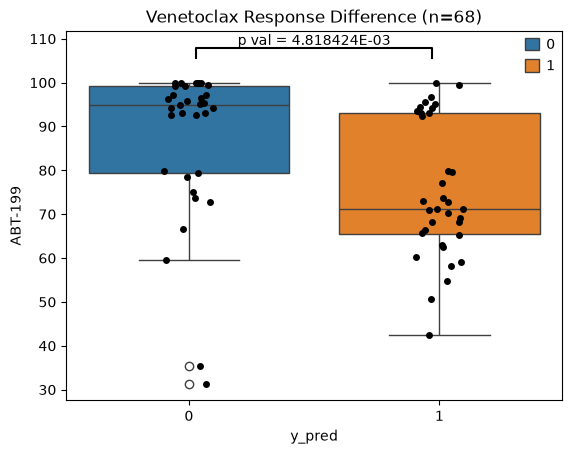

In [13]:
# analyze AUC differences
adata = mf_ad.copy()

#adata = adata[high_conf_results.index]
adata = adata[results_df['samples']]

adata.obs['y_pred'] = list(results_df['y_pred'])
adata.obs['y_prob'] = list(results_df['y_prob'])
adata.obs['y_true'] = list(results_df['y_true'])

fig, ax = plt.subplots(1)
plt.title(f'Venetoclax Response Difference (n={len(adata.obs)})')
sns.boxplot(adata.obs, y='ABT-199', x='y_pred', hue='y_pred')
sns.stripplot(adata.obs, y='ABT-199', x='y_pred',color='k')

test = ttest_ind(adata[adata.obs['y_pred'] == 1].obs['ABT-199'], adata[adata.obs['y_pred'] == 0].obs['ABT-199'])
annotation = (0, 1, f"p val = {test.pvalue:3E}")
starbars.draw_annotation([annotation])

2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03


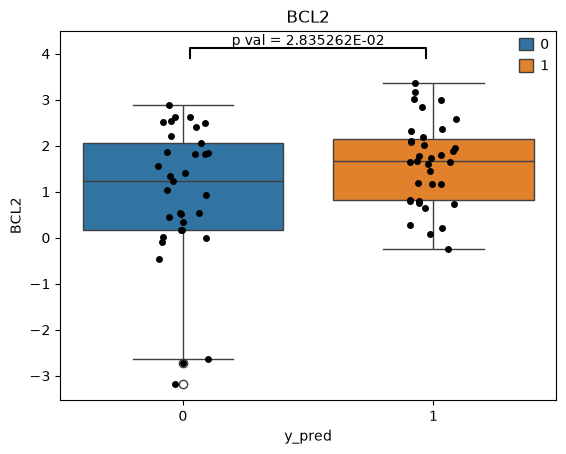

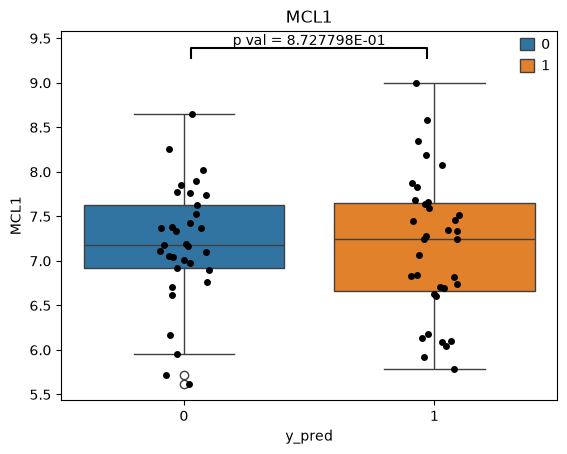

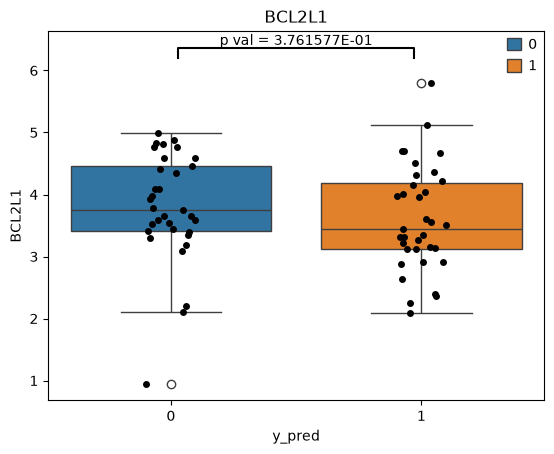

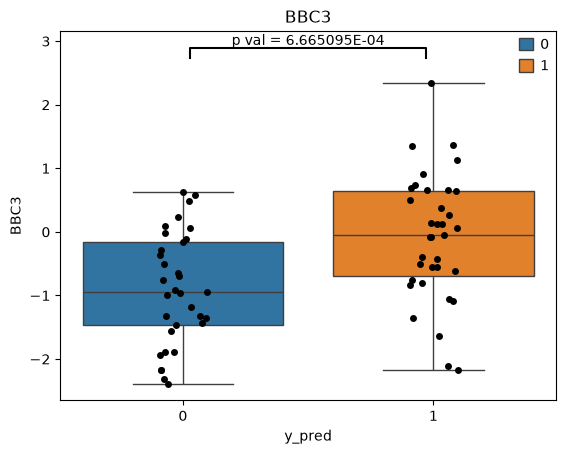

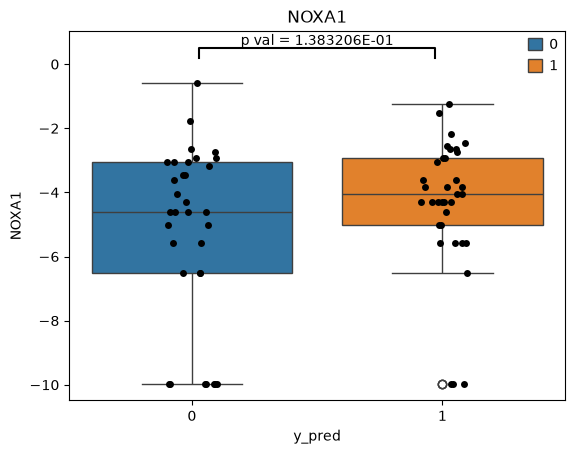

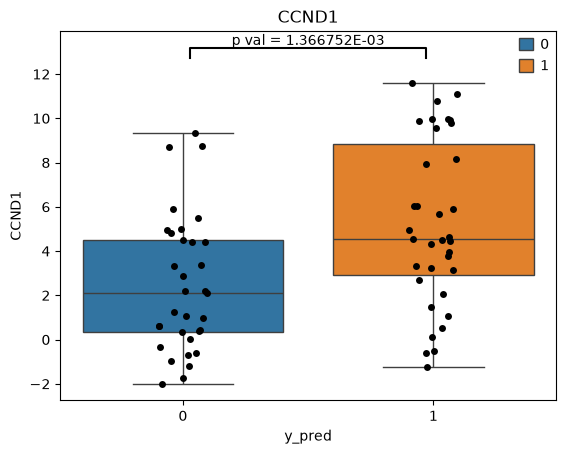

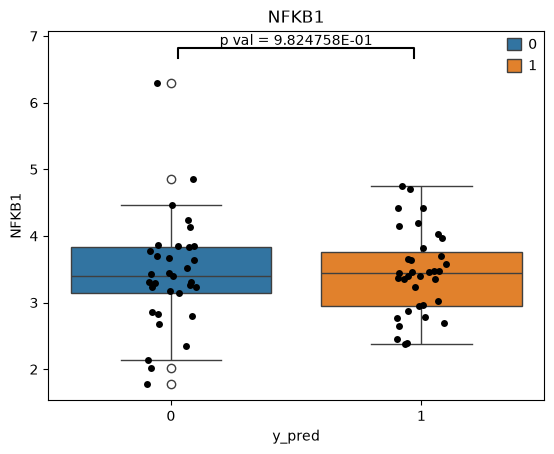

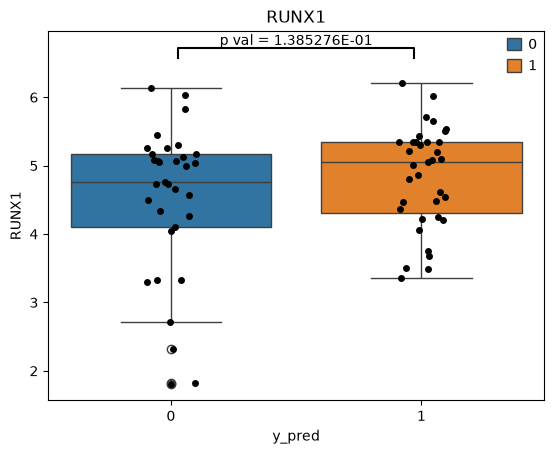

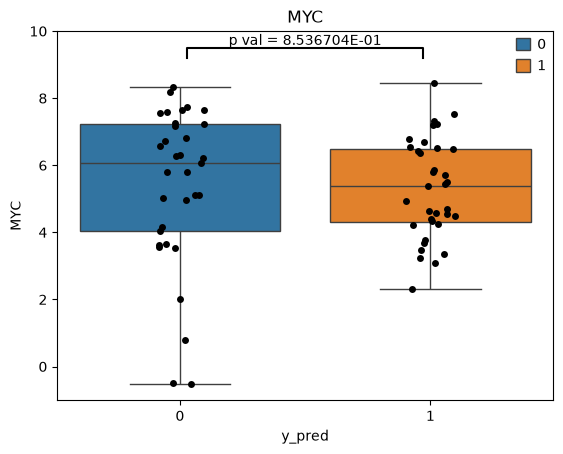

In [14]:
sensitive_ad = adata[adata.obs['y_pred'] == 1]
resistant_ad = adata[adata.obs['y_pred'] == 0]
# difference in mean expression of key genes
genes_of_interest = ["BCL2", "MCL1","BCL2L1", "BBC3", "NOXA1", "CCND1", 'NFKB1', "RUNX1", "MYC"]

for gene in genes_of_interest:
    test =  ttest_ind(sensitive_ad.to_df()[gene], resistant_ad.to_df()[gene], alternative='two-sided')
    
    fig, ax = plt.subplots(1)
    expr = adata.to_df()
    expr['y_pred'] = adata.obs['y_pred']

    plt.title(gene)
    sns.boxplot(expr, y=gene, x='y_pred', hue='y_pred')
    sns.stripplot(expr, y=gene, x='y_pred',color='k')

    annotation = (0, 1, f"p val = {test.pvalue:3E}")
    starbars.draw_annotation([annotation])




2.0 0.03
2.0 0.03


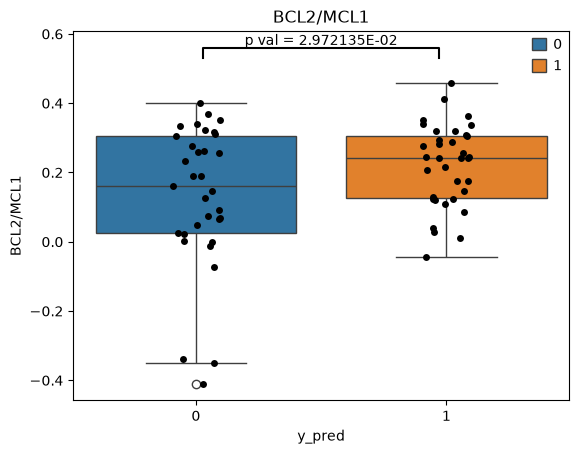

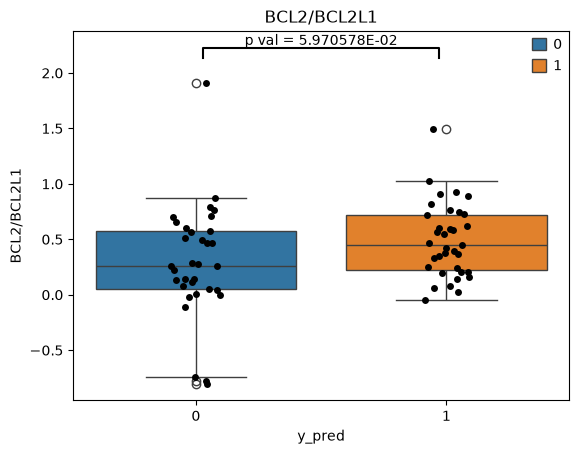

In [15]:
#adata = mf_ad.copy()
ratios  = ["BCL2/MCL1", "BCL2/BCL2L1"]

adata.obs['BCL2/MCL1'] = adata.to_df()['BCL2'] / adata.to_df()['MCL1']
adata.obs['BCL2/BCL2L1'] = adata.to_df()['BCL2'] / adata.to_df()['BCL2L1']



sensitive_ad = adata[adata.obs['y_pred'] == 1]
resistant_ad = adata[adata.obs['y_pred'] == 0]


for gene in ratios:
    test =  ttest_ind(sensitive_ad.obs[gene], resistant_ad.obs[gene], alternative='two-sided')
    
    fig, ax = plt.subplots(1)
    #expr = adata.to_df()
    #expr['y_pred'] = adata.obs['y_pred']

    plt.title(gene)
    sns.boxplot(adata.obs, y=gene, x='y_pred', hue='y_pred')
    sns.stripplot(adata.obs, y=gene, x='y_pred',color='k')

    annotation = (0, 1, f"p val = {test.pvalue:3E}")
    starbars.draw_annotation([annotation])


2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03
2.0 0.03


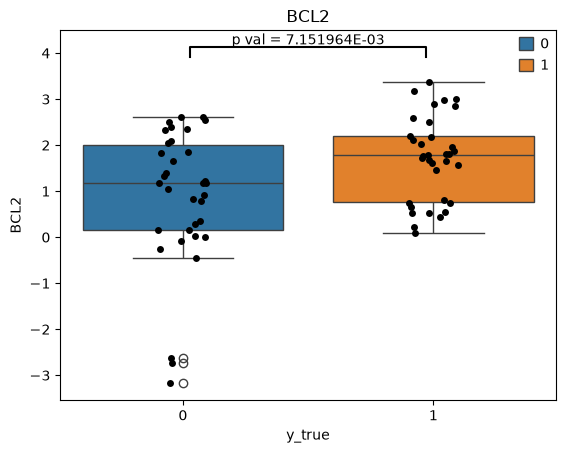

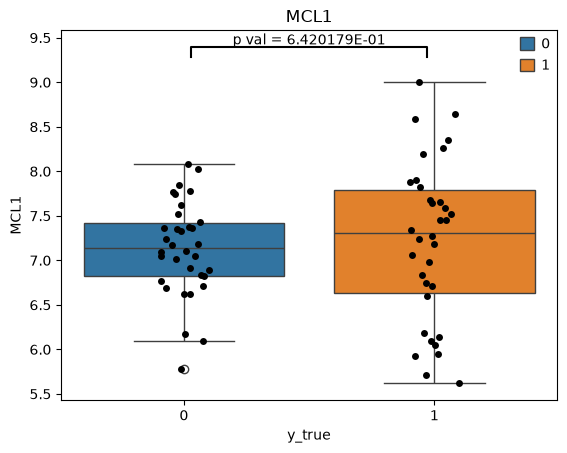

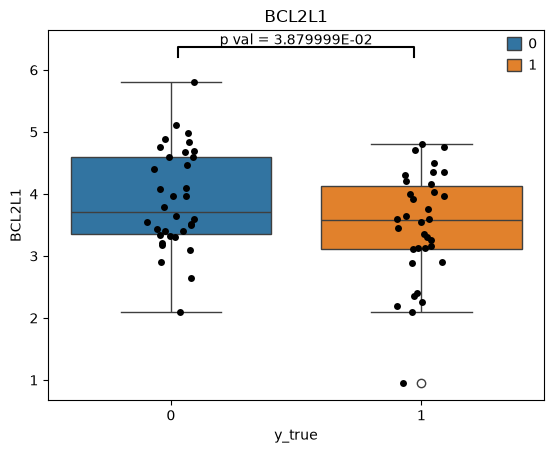

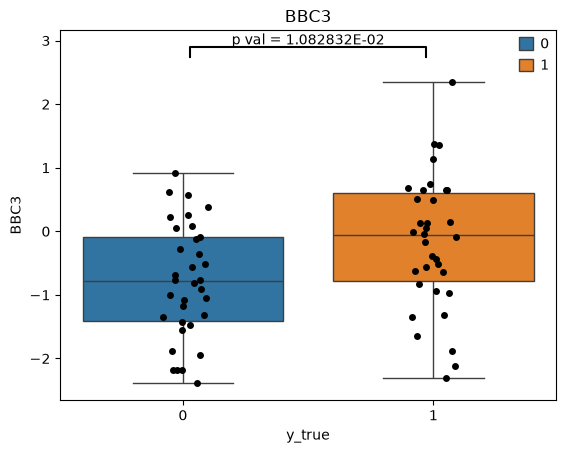

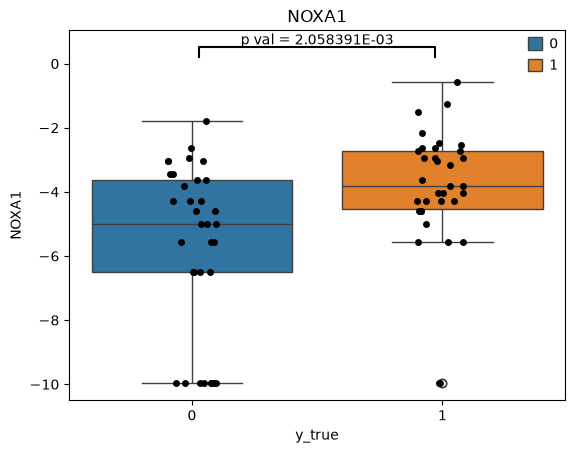

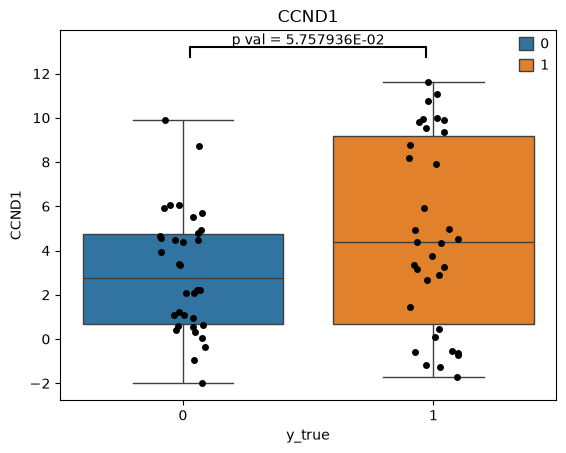

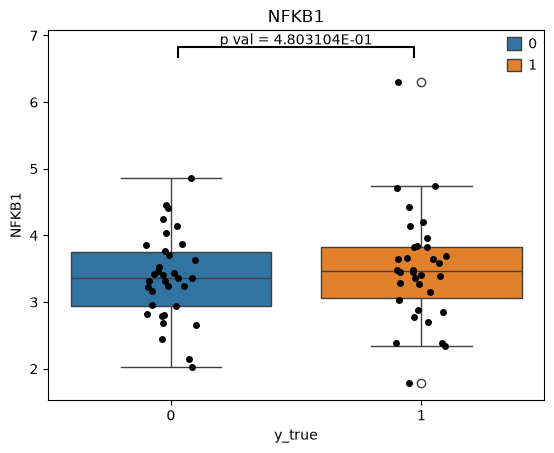

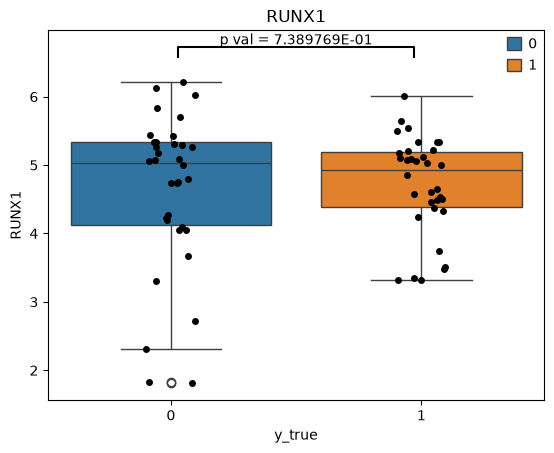

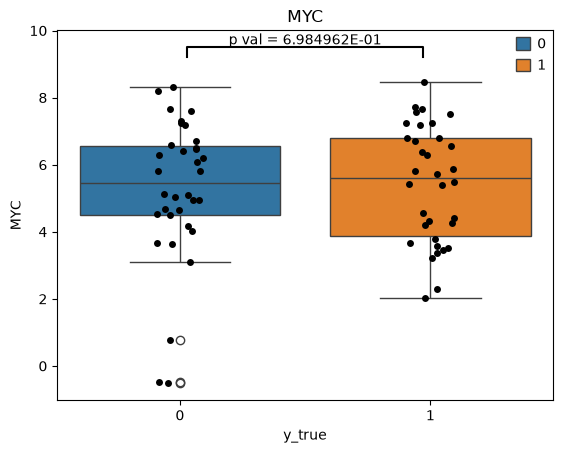

In [16]:
# true labels 

sensitive_ad = adata[adata.obs['y_true'] == 1]
resistant_ad = adata[adata.obs['y_true'] == 0]
# difference in mean expression of key genes
genes_of_interest = ["BCL2", "MCL1","BCL2L1", "BBC3", "NOXA1", "CCND1", 'NFKB1', "RUNX1", "MYC"]

for gene in genes_of_interest:
    test =  ttest_ind(sensitive_ad.to_df()[gene], resistant_ad.to_df()[gene], alternative='two-sided')
    
    fig, ax = plt.subplots(1)
    expr = adata.to_df()
    expr['y_true'] = adata.obs['y_true']

    plt.title(gene)
    sns.boxplot(expr, y=gene, x='y_true', hue='y_true')
    sns.stripplot(expr, y=gene, x='y_true',color='k')

    annotation = (0, 1, f"p val = {test.pvalue:3E}")
    starbars.draw_annotation([annotation])

2.0 0.03
2.0 0.03


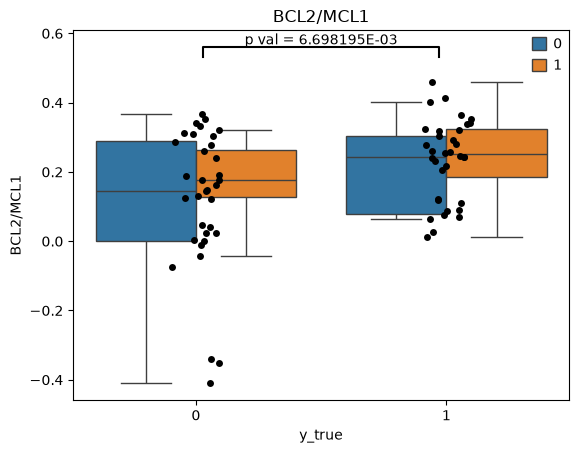

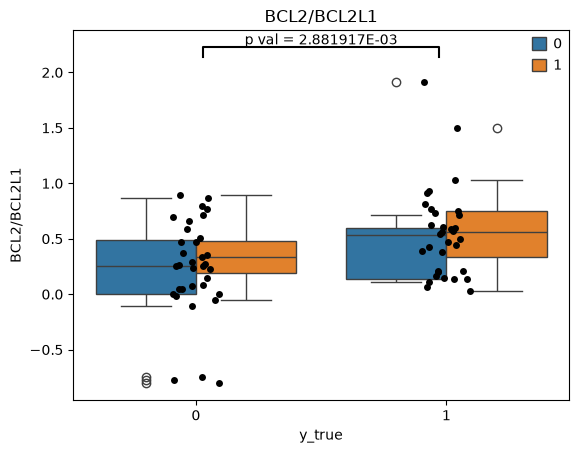

In [17]:
# true labels

ratios  = ["BCL2/MCL1", "BCL2/BCL2L1"]

adata.obs['BCL2/MCL1'] = adata.to_df()['BCL2'] / adata.to_df()['MCL1']
adata.obs['BCL2/BCL2L1'] = adata.to_df()['BCL2'] / adata.to_df()['BCL2L1']



sensitive_ad = adata[adata.obs['y_true'] == 1]
resistant_ad = adata[adata.obs['y_true'] == 0]


for gene in ratios:
    test =  ttest_ind(sensitive_ad.obs[gene], resistant_ad.obs[gene], alternative='two-sided')
    
    fig, ax = plt.subplots(1)
    #expr = adata.to_df()
    #expr['y_pred'] = adata.obs['y_pred']

    plt.title(gene)
    sns.boxplot(adata.obs, y=gene, x='y_true', hue='y_pred')
    sns.stripplot(adata.obs, y=gene, x='y_true',color='k')

    annotation = (0, 1, f"p val = {test.pvalue:3E}")
    starbars.draw_annotation([annotation])

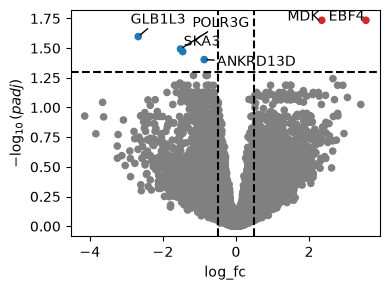

In [18]:
# limma for differential expression analysis
expr = adata.to_df()
design = np.column_stack([np.ones( len(adata.obs['y_pred']) ), np.array(adata.obs['y_pred']) ])

fit = pylimma.lm_fit(expr.transpose(), design)
fit = pylimma.contrasts_fit(fit, contrasts=np.array([[0], [1]]))
fit = pylimma.e_bayes(fit)

results_df = pylimma.top_table(fit,coef=0, key="fit",number=np.inf,sort_by="p")
results_df['padj'] = results_df["adj_p_value"]

dc.pl.volcano(data=results_df, x="log_fc", y="padj", top=30)
plt.show()


2026-10-17 14:38:58,703 [WARNING] Duplicated values found in preranked stats:
sample	ratio
log_fc         5.19%
ave_expr       6.40%
t              4.67%
p_value        4.79%
adj_p_value   69.96%
b              5.55%
padj          69.96%
The order of those genes will be arbitrary, which may produce unexpected results.


<Axes: title={'center': 'Predicted Sensitive vs. Resistant'}, xlabel='NES'>

<Figure size 640x480 with 0 Axes>

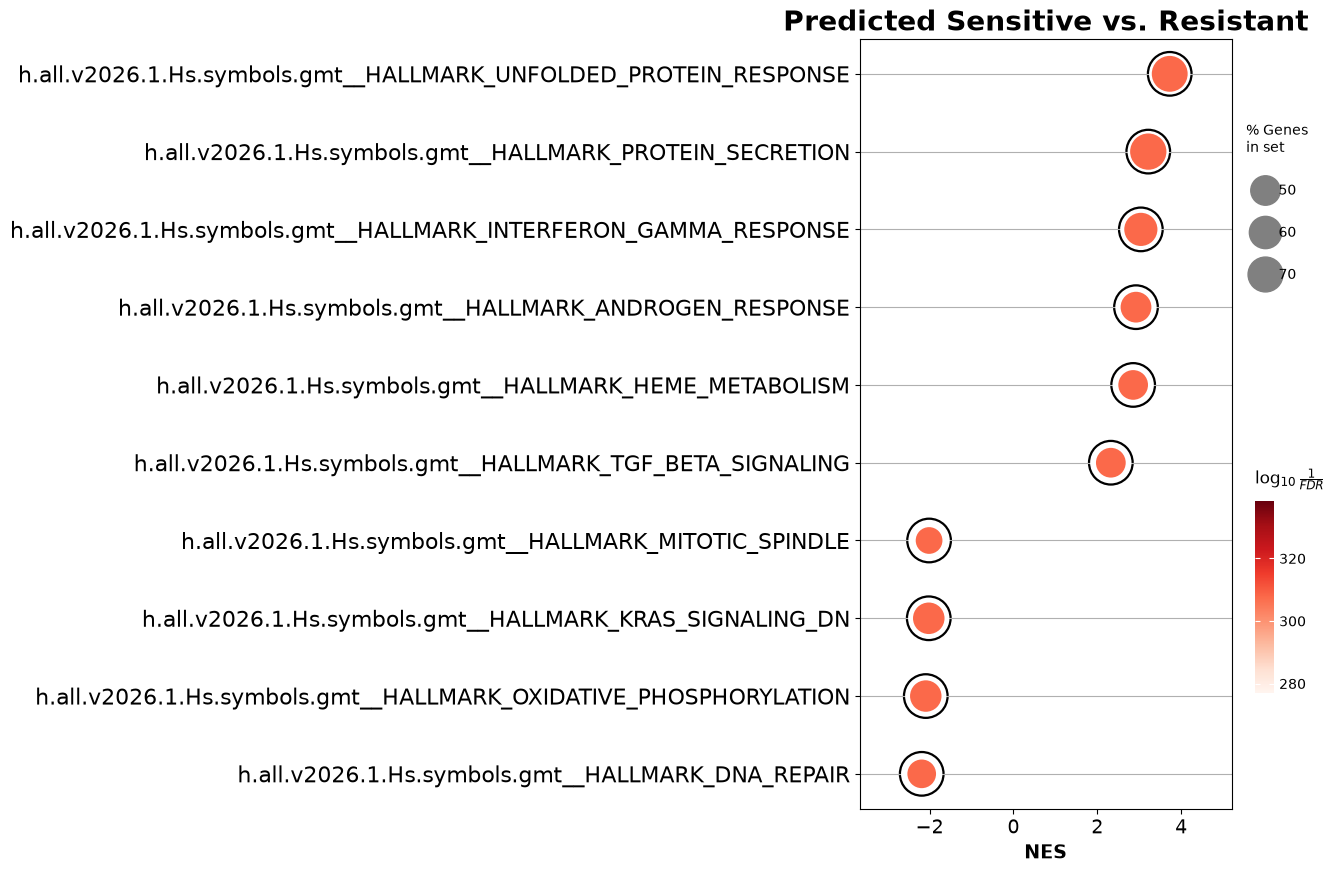

In [19]:
import json
# GSEA
plt.clf()
gmt_dir = "../../data/GMT/"
hallmark_gmt = gmt_dir + "h.all.v2026.1.Hs.symbols.gmt"
#gmt = gmt_dir+"msigdb.v2026.1.Hs.symbols.gmt"
#gene_set_path = gmt_dir + 'GO_Biological_Process_2026.json'

#with open(gene_set_path, 'r') as f:
#    gene_set = json.load(f)

results_df = results_df.sort_values(by="t")
pre_res = gp.prerank(rnk=results_df, gene_sets=[hallmark_gmt], threads=8, min_size=5, max_size=1000, outdir=None, seed=4)
pre_res.res2d = pre_res.res2d.sort_values(by="NES")
#pre_res.res2d["Term"] = (
#    pre_res.res2d["Term"]
    #.str.replace("h.all.v2026.1.Hs.symbols.gmt__HALLMARK_", "", regex=False)
#)


pre_res.res2d = pre_res.res2d.sort_values("FDR q-val").drop_duplicates(subset="Term")
pre_res.res2d = pre_res.res2d.sort_values(by="NES")



gp.dotplot(pre_res.res2d,column="FDR q-val",cmap="Reds", center=0, title='Predicted Sensitive vs. Resistant', size=5,figsize=(6, 10),cutoff=0.05,show_ring=True,)


In [20]:
results_df

,log_fc,ave_expr,t,p_value,adj_p_value,b,padj
gene,,,,,,,
GLB1L3,-2.674369,-8.569088,-5.018935,0.000004,0.025271,3.960564,0.025271
POLR3G,-1.515899,0.707666,-4.878455,0.000007,0.032147,3.501415,0.032147
SKA3,-1.457285,-0.061464,-4.804951,0.000009,0.033824,3.263339,0.033824
ANKRD13D,-0.868568,2.435654,-4.713886,0.000013,0.039483,2.970560,0.039483
COLGALT1,-0.818482,3.095037,-4.538763,0.000024,0.053732,2.414740,0.053732
...,...,...,...,...,...,...,...
MID2,1.386012,1.343329,4.277099,0.000061,0.064996,1.603530,0.064996
PCDHGB6,1.491182,-1.201288,4.292892,0.000058,0.064996,1.651793,0.064996
SOCS1,2.654111,-2.658933,4.472182,0.000031,0.057157,2.206048,0.057157


Text(0.5, 0, 'Enrichment Score')

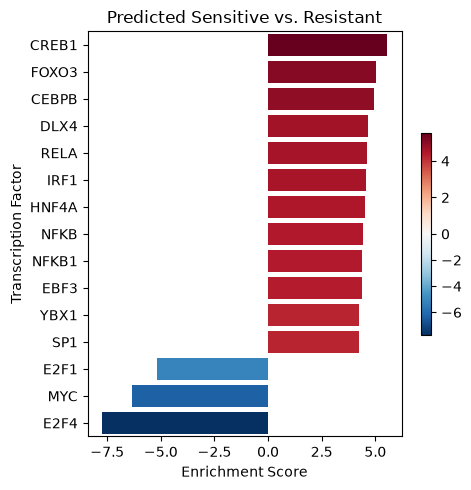

In [21]:

collectri = dc.op.collectri(organism='human')
input_for_tf = results_df[['t']].T.rename(index={"t": "sensitive.vs.resistant"})
tf_acts, tf_padj = dc.mt.ulm(data=input_for_tf, net=collectri)
msk = (tf_padj.T < 0.05).iloc[:,0]
tf_acts = tf_acts.loc[:,msk]
fig = dc.pl.barplot(data=tf_acts, name="sensitive.vs.resistant", return_fig = True, top=15, figsize=(5,5))

plt.title('Predicted Sensitive vs. Resistant')
plt.ylabel('Transcription Factor')
plt.xlabel("Enrichment Score")


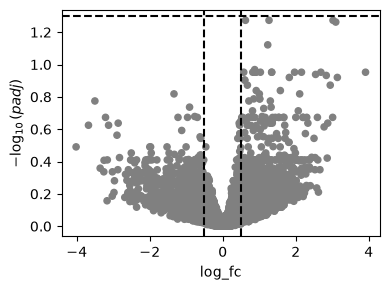

In [22]:
# DGE analysis of true label groups

# limma for differential expression analysis
expr = adata.to_df()
design = np.column_stack([np.ones( len(adata.obs['y_true']) ), np.array(adata.obs['y_true']) ])

fit = pylimma.lm_fit(expr.transpose(), design)
fit = pylimma.contrasts_fit(fit, contrasts=np.array([[0], [1]]))
fit = pylimma.e_bayes(fit)

results_df = pylimma.top_table(fit,coef=0, key="fit",number=np.inf,sort_by="p")
results_df['padj'] = results_df["adj_p_value"]

dc.pl.volcano(data=results_df, x="log_fc", y="padj", top=30)
plt.show()

2026-10-17 14:39:53,394 [WARNING] Duplicated values found in preranked stats:
sample	ratio
log_fc         5.53%
ave_expr       6.40%
t              4.58%
p_value        4.71%
adj_p_value   87.20%
b              5.70%
padj          87.20%
The order of those genes will be arbitrary, which may produce unexpected results.


<Axes: title={'center': 'True labels Sensitive vs. Resistant'}, xlabel='NES'>

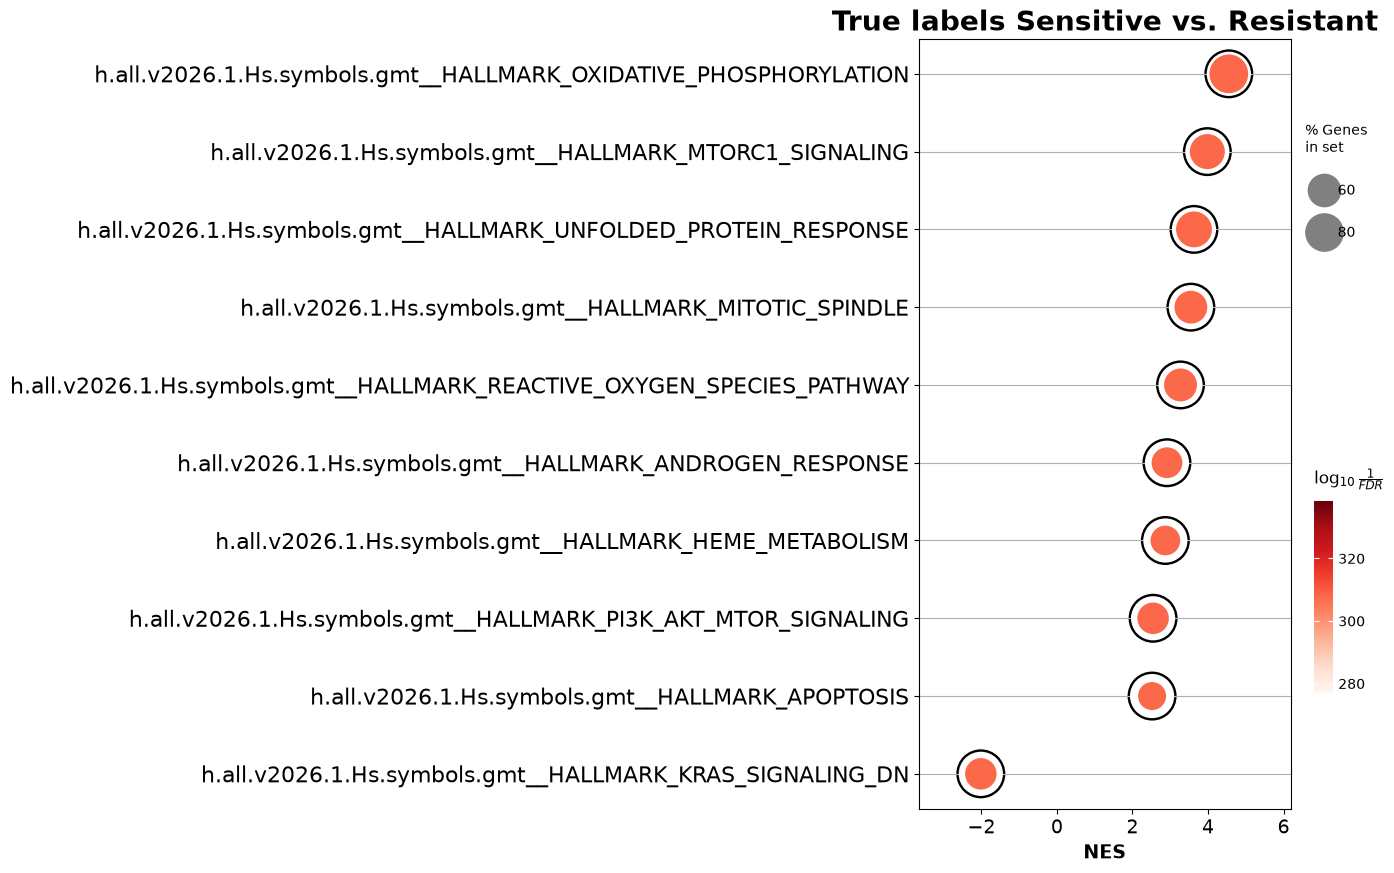

In [23]:
results_df = results_df.sort_values(by="t")
pre_res = gp.prerank(rnk=results_df, gene_sets=[hallmark_gmt], threads=8, min_size=5, max_size=1000, outdir=None, seed=4)
pre_res.res2d = pre_res.res2d.sort_values(by="NES")
#pre_res.res2d["Term"] = (
#    pre_res.res2d["Term"]
    #.str.replace("h.all.v2026.1.Hs.symbols.gmt__HALLMARK_", "", regex=False)
#)


pre_res.res2d = pre_res.res2d.sort_values("FDR q-val").drop_duplicates(subset="Term")
pre_res.res2d = pre_res.res2d.sort_values(by="NES")



gp.dotplot(pre_res.res2d,column="FDR q-val",cmap="Reds", center=0, title='True labels Sensitive vs. Resistant', size=5,figsize=(6, 10),cutoff=0.05,show_ring=True,)


Text(0.5, 0, 'Enrichment Score')

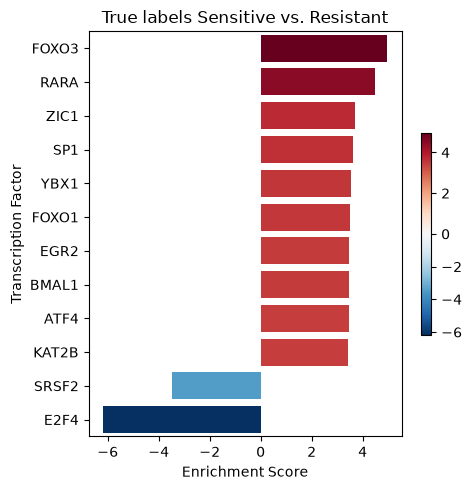

In [24]:
collectri = dc.op.collectri(organism='human')
input_for_tf = results_df[['t']].T.rename(index={"t": "sensitive.vs.resistant"})
tf_acts, tf_padj = dc.mt.ulm(data=input_for_tf, net=collectri)
msk = (tf_padj.T < 0.05).iloc[:,0]
tf_acts = tf_acts.loc[:,msk]
fig = dc.pl.barplot(data=tf_acts, name="sensitive.vs.resistant", return_fig = True, top=15, figsize=(5,5))

plt.title('True labels Sensitive vs. Resistant')
plt.ylabel('Transcription Factor')
plt.xlabel("Enrichment Score")

In [25]:
dge_results = differential_expression_analysis(method='t_test', adata = adata)

/home/braemp4/.cache/pypoetry/virtualenvs/venetoclax-project-Qra0yt8T-py3.14/lib/python3.14/site-packages/scipy/stats/_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/tmp/ipykernel_13149/3521235299.py:181: RuntimeWarning: invalid value encountered in log2
  analysis_results['log_fc'] = np.log2(fc)


2026-10-17 14:48:50,479 [WARNING] Input data contains NA, filled NA with 0
2026-10-17 14:48:50,499 [WARNING] Duplicated values found in preranked stats:
sample	ratio
t         5.55%
padj     98.47%
log_fc    7.97%
The order of those genes will be arbitrary, which may produce unexpected results.


<Axes: title={'center': 'Predicted Sensitive vs. Resistant'}, xlabel='NES'>

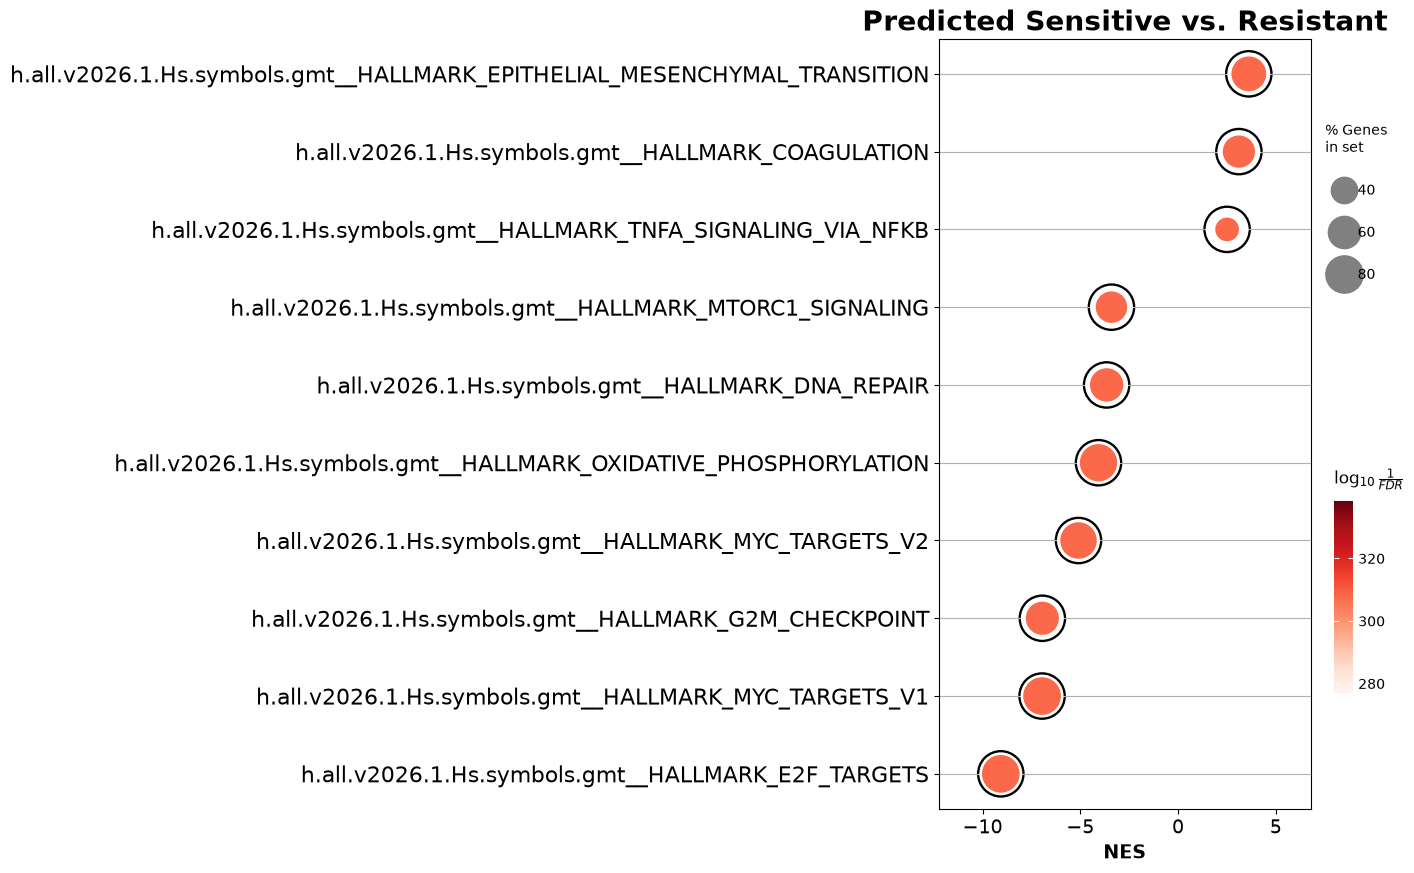

In [26]:
gmt = gmt_dir + "msigdb.v2026.1.Hs.symbols.gmt"

dge_results = dge_results.sort_values(by="t")


pre_res = gp.prerank(rnk=dge_results, gene_sets=[hallmark_gmt], threads=8, min_size=5, max_size=1000, outdir=None, seed=4)
pre_res.res2d = pre_res.res2d.sort_values(by="NES")
#pre_res.res2d["Term"] = (
#    pre_res.res2d["Term"]
    #.str.replace("h.all.v2026.1.Hs.symbols.gmt__HALLMARK_", "", regex=False)
#)


pre_res.res2d = pre_res.res2d.sort_values("FDR q-val").drop_duplicates(subset="Term")
pre_res.res2d = pre_res.res2d.sort_values(by="NES")



gp.dotplot(pre_res.res2d,column="FDR q-val",cmap="Reds", center=0, title='Predicted Sensitive vs. Resistant', size=5,figsize=(6, 10),cutoff=0.05,show_ring=True,)

/home/braemp4/.cache/pypoetry/virtualenvs/venetoclax-project-Qra0yt8T-py3.14/lib/python3.14/site-packages/scipy/stats/_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/home/braemp4/.cache/pypoetry/virtualenvs/venetoclax-project-Qra0yt8T-py3.14/lib/python3.14/site-packages/statsmodels/stats/multitest.py:229: RuntimeWarning: divide by zero encountered in log1p
  pvals_corrected_raw = -np.expm1(np.arange(ntests, 0, -1) * np.log1p(-pvals))
/tmp/ipykernel_13149/3521235299.py:181: RuntimeWarning: invalid value encountered in log2
  analysis_results['log_fc'] = np.log2(fc)
2026-10-17 14:57:44,108 [WARNING] Input data contains NA, filled NA with 0
2026-10-17 14:57:44,124 [WARNING] Duplicated values found in preranked stats:
sample	ratio
t         5.62%
padj     99.39%
log_fc    7.92%
The order of those gene

<Axes: title={'center': 'True labels Sensitive vs. Resistant'}, xlabel='NES'>

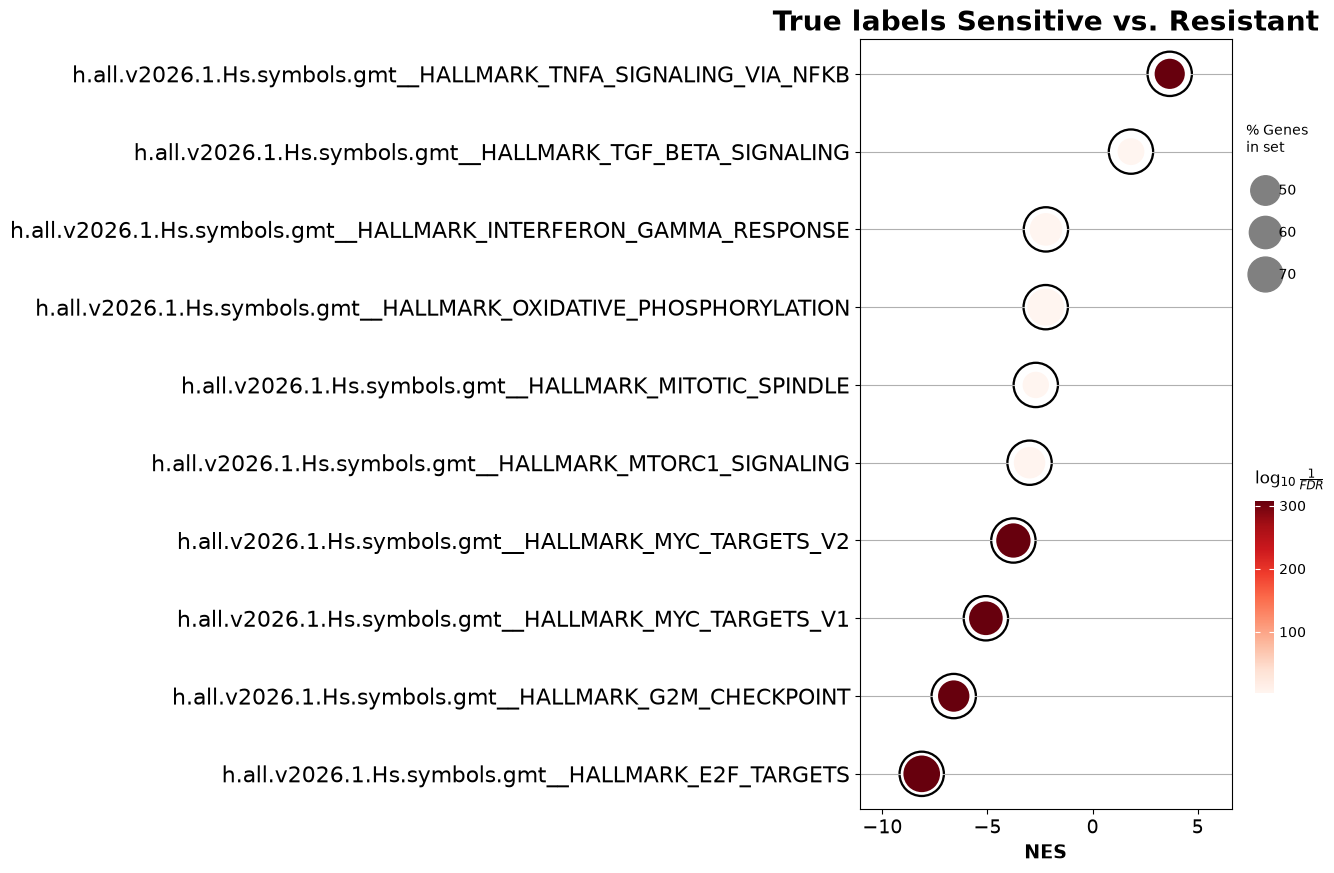

In [27]:
# differential expression using t test with true labels 
dge_results = differential_expression_analysis(method='t_test', adata = adata, group_label='y_true')

dge_results = dge_results.sort_values(by="t")


pre_res = gp.prerank(rnk=dge_results, gene_sets=[hallmark_gmt], threads=8, min_size=5, max_size=1000, outdir=None, seed=4)
pre_res.res2d = pre_res.res2d.sort_values(by="NES")
#pre_res.res2d["Term"] = (
#    pre_res.res2d["Term"]
    #.str.replace("h.all.v2026.1.Hs.symbols.gmt__HALLMARK_", "", regex=False)
#)


pre_res.res2d = pre_res.res2d.sort_values("FDR q-val").drop_duplicates(subset="Term")
pre_res.res2d = pre_res.res2d.sort_values(by="NES")



gp.dotplot(pre_res.res2d,column="FDR q-val",cmap="Reds", center=0, title='True labels Sensitive vs. Resistant', size=5,figsize=(6, 10),cutoff=0.05,show_ring=True,)

Text(0.5, 0, 'Enrichment Score')

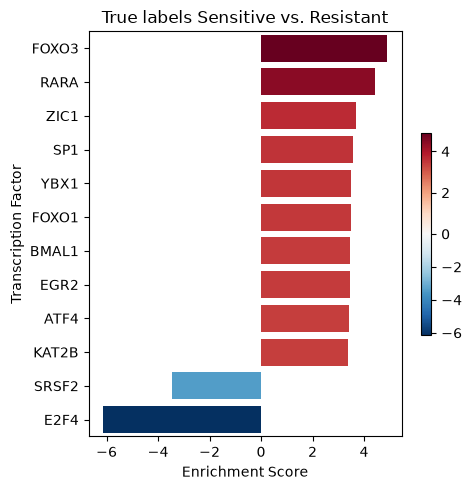

In [28]:
collectri = dc.op.collectri(organism='human')
input_for_tf =dge_results[['t']].T.rename(index={"t": "sensitive.vs.resistant"})
tf_acts, tf_padj = dc.mt.ulm(data=input_for_tf, net=collectri)
msk = (tf_padj.T < 0.05).iloc[:,0]
tf_acts = tf_acts.loc[:,msk]
fig = dc.pl.barplot(data=tf_acts, name="sensitive.vs.resistant", return_fig = True, top=15, figsize=(5,5))

plt.title('True labels Sensitive vs. Resistant')
plt.ylabel('Transcription Factor')
plt.xlabel("Enrichment Score")